# Motores ejecutivos: decisiones, restricciones y sensibilidad

## Alcance
Se recalculan los **15 motores de decisión** desarrollados esta semana con inputs sintéticos nuevos. Cada sección plantea qué input cambia la decisión y qué invariante debe mantenerse. No se construye un puntaje conjunto entre métricas de unidades distintas ni se interpreta una optimización ilustrativa como recomendación corporativa.

Se usan las implementaciones existentes de cada proyecto; no se copian sus algoritmos. Las pruebas unitarias siguen siendo una capa separada. El valor de este notebook es hacer visible la frontera de decisiones, incluidos rechazos, opciones de no invertir y costos de ejecución.

In [1]:
from pathlib import Path
import sys,importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if ROOT.name!='06-strategy-innovation-and-leadership':
    ROOT=next(p/'06-strategy-innovation-and-leadership' for p in [ROOT,*ROOT.parents] if (p/'06-strategy-innovation-and-leadership').is_dir())
plt.rcParams.update({'font.size':11,'axes.spines.top':False,'axes.spines.right':False})
def load_engine(folder,filename):
    path=ROOT/folder/'src'/filename
    name='weekly_'+folder.replace('-','_')
    spec=importlib.util.spec_from_file_location(name,path);module=importlib.util.module_from_spec(spec)
    sys.modules[name]=module;spec.loader.exec_module(module)
    return module


## 01. Opciones reales: esperar también tiene valor
El motor calcula una expectativa física ajustada por una tasa suministrada; no es precio de una opción negociada bajo medida neutral al riesgo. Se varía PV inicial manteniendo costo=100, horizonte=3 y dinámica binomial. La opción de esperar debe valer al menos el ejercicio inmediato no negativo.

In [2]:
real=load_engine('01-capital-allocation-real-options','capital_allocation.py')
rows=[]
for pv in [60,80,100,120,150,200]:
    result=real.solve(real.InvestmentCase(pv,100,1.25,.8,.5,.08,3))
    assert result['option_value']>=max(pv-100,0)-1e-10
    rows.append(dict(PV=pv,immediate=max(pv-100,0),**result))
real_table=pd.DataFrame(rows);display(real_table)


,PV,immediate,option_value,immediate_npv,action
0,60,0,1.690021,-40,wait
1,80,0,5.530977,-20,wait
2,100,0,16.899696,0,wait
3,120,20,28.473494,20,wait
4,150,50,53.004707,50,wait
5,200,100,100.000000,100,invest


## 02. Entrada de mercado: guardar todos los equilibrios
Se cambia el costo de entrada simultánea en un juego de coordinación. Listar sólo un equilibrio produciría una recomendación dependiente de la inicialización. El mixto se muestra cuando el método lo identifica de forma interior; None no demuestra inexistencia de familias degeneradas.

In [3]:
entry=load_engine('02-market-entry-game-theory','market_entry.py')
rows=[]
for collision in [0.,1.,2.,4.,8.]:
    game=[[(0,0),(0,2)],[(2,0),(2-collision,2-collision)]]
    rows.append(dict(collision_cost=collision,pure=entry.pure_nash(game),mixed=entry.mixed_nash(game),dominance=entry.dominance(game)))
display(pd.DataFrame(rows))

,collision_cost,pure,mixed,dominance
0,0.0,"[(1, 1)]",None,"{'row': 1, 'column': 1}"
1,1.0,"[(1, 1)]",None,"{'row': 1, 'column': 1}"
2,2.0,"[(0, 1), (1, 0), (1, 1)]",None,"{'row': None, 'column': None}"
3,4.0,"[(0, 1), (1, 0)]","{'row_action_0_probability': 0.5, 'column_acti...","{'row': None, 'column': None}"
4,8.0,"[(0, 1), (1, 0)]","{'row_action_0_probability': 0.75, 'column_act...","{'row': None, 'column': None}"


## 03. Venture: correlación de exits, no de todos los defaults
El factor común correlaciona magnitudes de salida entre startups supervivientes. La probabilidad de fallo del código se simula independientemente por startup; no se la presenta como default sistémico correlacionado. Se guardan 10 semillas para comparar media y dispersión de pérdida/ES con la misma cartera.

In [4]:
venture=load_engine('03-venture-portfolio-construction','venture_portfolio.py')
starts=[venture.Startup(f'S{i}',10,.35,.8,.8) for i in range(8)]
rows=[]
for correlation in [0.,.25,.5,.9]:
    for seed in range(10):
        out=venture.simulate(starts,scenarios=1500,correlation=correlation,seed=20261018+seed)
        rows.append(dict(correlation=correlation,seed=seed,**out))
venture_table=pd.DataFrame(rows)
display(venture_table.groupby('correlation')[['expected_profit','loss_probability','expected_shortfall_loss']].agg(['mean','std']).round(4))

expected_profit          ... expected_shortfall_loss        
                       mean     std  ...                    mean     std
correlation                          ...                                
0.00                79.5238  1.8463  ...                 36.7067  1.9838
0.25                79.1050  2.2943  ...                 45.1003  1.7885
0.50                78.9311  2.9022  ...                 51.4734  1.6699
0.90                78.6360  4.0832  ...                 59.0250  1.4829

[4 rows x 6 columns]

## 04. Inversión en datos: prerrequisitos y presupuesto
Se contrasta selección exacta de tres iniciativas con beneficios bajo dos escenarios. La opción de no invertir está permitida. Los beneficios son supuestos de un business case y no ROI causal observado.

In [5]:
data=load_engine('04-data-investment-prioritization','investment_prioritization.py')
items=[data.Initiative('foundation',3,(5,3)),data.Initiative('model',4,(12,6),('foundation',)),data.Initiative('dashboard',4,(7,5))]
rows=[]
for budget in range(0,13):
    out=data.optimize(items,budget,(.6,.4));assert out['total_cost']<=budget
    if 'model' in out['selected']:assert 'foundation' in out['selected']
    rows.append(dict(budget=budget,**out))
display(pd.DataFrame(rows))

,budget,selected,total_cost,expected_net_benefit,unused_budget
0,0,(),0,0.0,0
1,1,(),0,0.0,1
2,2,(),0,0.0,2
3,3,"(foundation,)",3,1.2,0
4,4,"(dashboard,)",4,2.2,0
5,5,"(dashboard,)",4,2.2,1
6,6,"(dashboard,)",4,2.2,2
7,7,"(foundation, model)",7,6.8,0
8,8,"(foundation, model)",7,6.8,1
9,9,"(foundation, model)",7,6.8,2


## 05. Resiliencia: retrasos de cobro y piso de caja
La probabilidad reportada es la suma de pesos de escenarios prefijados con breach. No es una frecuencia estimada de insolvencia. Se mantiene el ingreso esperado mensual y se cambia el retraso de cobro del escenario adverso.

In [6]:
resilience=load_engine('05-strategic-resilience-stress-testing','resilience.py')
rows=[]
for delay in range(5):
    scenarios=[resilience.Scenario('base',.7,1,1),resilience.Scenario('late',.3,.8,1,delay)]
    out=resilience.evaluate(20,10,8,12,scenarios,minimum_cash=0)
    rows.append(dict(delay=delay,breach_probability=out['breach_probability'],expected_cash=out['expected_ending_cash']))
display(pd.DataFrame(rows))

,delay,breach_probability,expected_cash
0,0,0.0,36.8
1,1,0.0,34.4
2,2,0.0,32.0
3,3,0.3,29.6
4,4,0.3,27.2


## 06. Capital corporativo: EVA y costo de oportunidad
Un proyecto con NOPAT positivo puede destruir EVA cuando WACC×capital supera NOPAT. Se varía WACC, dejando presupuesto y beneficios fijos. El óptimo vacío se conserva si no hay creación de valor bajo esos supuestos.

In [7]:
capital=load_engine('06-enterprise-capital-allocation-roic','capital.py')
rows=[]
for wacc in [.02,.08,.15,.25,.4]:
    units=[capital.BusinessUnit('A',10,3,wacc),capital.BusinessUnit('B',8,1.5,wacc)]
    out=capital.allocate(units,18);rows.append(dict(WACC=wacc,**out))
display(pd.DataFrame(rows))

,WACC,selected,capital_used,expected_eva,capital_remaining,unit_roic
0,0.02,"(A, B)",18,4.14,0,"{'A': 0.3, 'B': 0.1875}"
1,0.08,"(A, B)",18,3.06,0,"{'A': 0.3, 'B': 0.1875}"
2,0.15,"(A, B)",18,1.80,0,"{'A': 0.3, 'B': 0.1875}"
3,0.25,"(A,)",10,0.50,8,"{'A': 0.3, 'B': 0.1875}"
4,0.40,(),0,0.00,18,"{'A': 0.3, 'B': 0.1875}"


## 07. OKR: pesos y saturación
Se varía el peso de un objetivo rezagado frente a otro completo. El total ponderado no debe reemplazar la lectura de alertas individuales. Clipping a [0,1] significa que sobrecumplimiento no compensa objetivos de manera ilimitada.

In [8]:
okr=load_engine('07-executive-strategy-okr-operating-system','okr.py')
rows=[]
for weight in [.1,.5,1,2,5]:
    items=[okr.KeyResult('Revenue','CEO',100,200,130,weight),okr.KeyResult('Cost','CFO',100,80,80,1,'decrease')]
    out=okr.evaluate(items);assert 0<=out['overall_progress']<=1
    rows.append(dict(revenue_weight=weight,overall=out['overall_progress'],attention=out['attention_count']))
display(pd.DataFrame(rows))

,revenue_weight,overall,attention
0,0.1,0.936364,1
1,0.5,0.766667,1
2,1.0,0.650000,1
3,2.0,0.533333,1
4,5.0,0.416667,1


## 08. Apetito: desigualdad estricta en el límite
El motor usa breach para utilización >1 y warning en el límite. Se prueban valores alrededor del umbral y una métrica inferior sin denominador positivo. Las reglas son un contrato ilustrativo y deben coincidir con el manual de apetito aprobado en una aplicación.

In [9]:
appetite=load_engine('08-enterprise-risk-appetite-board-reporting','risk_appetite.py')
rows=[]
for observed in [.079,.08,.099999,.1,.100001,.12]:
    out=appetite.assess([appetite.RiskMetric('NPL',observed,.1)])
    rows.append(dict(observed=observed,**out['metrics'][0]))
display(pd.DataFrame(rows))
assert appetite.assess([appetite.RiskMetric('LCR',0,1,direction='lower')])['breaches']==1

,observed,metric,utilization,status,escalation
0,0.079000,NPL,0.79000,within_appetite,none
1,0.080000,NPL,0.80000,within_appetite,none
2,0.099999,NPL,0.99999,warning,risk_committee
3,0.100000,NPL,1.00000,warning,risk_committee
4,0.100001,NPL,1.00001,breach,board
5,0.120000,NPL,1.20000,breach,board


## 09. Unit economics: churn cero no implica LTV identificable
El modelo geométrico LTV=contribución/churn diverge al aproximarse churn a cero. El código devuelve None cuando churn=0 en lugar de fabricar un múltiplo. Se conserva esa distinción en la tabla y no se anualiza una tasa mensual sin declarar hipótesis.

In [10]:
unit=load_engine('09-business-unit-economics-pricing','unit_economics.py')
rows=[]
for churn in [0.,.01,.03,.1,.2]:
    out=unit.analyze([unit.Segment('SMB',100,20,8,30,500,churn)])
    rows.append(dict(monthly_churn=churn,**out['segments'][0]))
display(pd.DataFrame(rows))

,monthly_churn,segment,contribution_per_customer,operating_profit,break_even_customers,ltv_before_cac,ltv_to_cac
0,0.00,SMB,12,700,42,NaN,NaN
1,0.01,SMB,12,700,42,1200.0,40.000000
2,0.03,SMB,12,700,42,400.0,13.333333
3,0.10,SMB,12,700,42,120.0,4.000000
4,0.20,SMB,12,700,42,60.0,2.000000


## 10. Recuperación: implementar tarde tiene costo de liquidez
Una acción puede mejorar caja terminal y aun fallar en prevenir el primer breach. Se varía el mes de implementación con costo inicial 4 y ahorro mensual 5. El horizonte y el piso permanecen fijos.

In [11]:
recovery=load_engine('10-crisis-management-recovery-planning','recovery.py')
rows=[]
for month in [1,2,3,4,6]:
    out=recovery.plan(15,5,9,8,[recovery.RecoveryAction('cuts',4,5,month)])
    rows.append(dict(implementation_month=month,ending_cash=out['ending_cash'],first_breach=out['first_breach_month'],success=out['recovery_achieved']))
recovery_table=pd.DataFrame(rows);display(recovery_table)

,implementation_month,ending_cash,first_breach,success
0,1,19,NaN,True
1,2,14,NaN,True
2,3,9,NaN,True
3,4,4,NaN,True
4,6,-6,4.0,False


## 11. Planeación: capital de trabajo consume caja durante crecimiento
Se mantiene margen y capex, y se varía el ratio de capital de trabajo con crecimiento anual 15%. No se confunde utilidad con flujo de caja. Los inputs son ratios hipotéticos, sin múltiplos de valoración externos.

In [12]:
strategy=load_engine('11-corporate-strategic-planning','strategic_plan.py')
rows=[]
for working_capital in [0.,.1,.3,.5,.8]:
    scenario=strategy.Scenario('base',1,(.15,.15,.15),(.2,.2,.2),(.05,.05,.05),working_capital)
    out=strategy.forecast(100,10,.3,[scenario])
    rows.append(dict(working_capital_ratio=working_capital,terminal_cash=out['expected_terminal_cash']))
display(pd.DataFrame(rows))

,working_capital_ratio,terminal_cash
0,0.0,45.940375
1,0.1,40.731625
2,0.3,30.314125
3,0.5,19.896625
4,0.8,4.270375


## 12. Balance: frontera discreta de asignación de capital
Se asigna volumen a dos líneas bajo capital mínimo hipotético 12%. La enumeración es exacta en la malla entera; una solución discreta no equivale al óptimo continuo. Se verifica factibilidad en todos los presupuestos.

In [13]:
balance=load_engine('12-balance-sheet-capital-management','capital_management.py')
lines=[balance.BusinessLine('A',10,3,10),balance.BusinessLine('B',15,5,10)]
rows=[]
for available in [0.,3.,6.,9.,12.,18.]:
    out=balance.optimize(available,.12,lines)
    assert out['rwa']<=out['rwa_capacity']+1e-10
    rows.append(dict(capital=available,**out))
balance_table=pd.DataFrame(rows);display(balance_table)

,capital,expected_profit,rwa,allocation,capital_ratio,rwa_capacity
0,0.0,0.0,0.0,{},NaN,0.0
1,3.0,8.0,25.0,"{'A': 1, 'B': 1}",0.12,25.0
2,6.0,16.0,50.0,"{'A': 2, 'B': 2}",0.12,50.0
3,9.0,25.0,75.0,"{'A': 0, 'B': 5}",0.12,75.0
4,12.0,33.0,100.0,"{'A': 1, 'B': 6}",0.12,100.0
5,18.0,50.0,150.0,"{'A': 0, 'B': 10}",0.12,150.0


## 13. Incentivos: malus y override de cumplimiento
El objetivo no es maximizar el bono sino hacer explícita la respuesta del contrato a pérdidas y breaches. Se varía el ratio de pérdida y se confirma que una infracción de cumplimiento anula el bono incluso con alto score financiero.

In [14]:
incentive=load_engine('13-executive-incentive-design','incentives.py')
rows=[]
for loss in [0.,.1,.25,.5,.75]:
    out=incentive.calculate([incentive.ExecutiveScore('CEO',100,.5,1.2,1.,loss)])
    rows.append(dict(loss_ratio=loss,**out['executives'][0]))
display(pd.DataFrame(rows))
assert incentive.calculate([incentive.ExecutiveScore('CEO',100,1,2,2,0,True)])['total_bonus']==0

,loss_ratio,name,bonus,paid_now,deferred,risk_factor
0,0.00,CEO,56.0,33.60,22.40,1.0
1,0.10,CEO,44.8,26.88,17.92,0.8
2,0.25,CEO,28.0,16.80,11.20,0.5
3,0.50,CEO,0.0,0.00,0.00,0.0
4,0.75,CEO,0.0,0.00,0.00,0.0


## 14. M&A: sinergias ponderadas frente a probabilidad de destruir valor
Se conserva un caso adverso y otro base, variando precio de compra. Un NPV esperado positivo no garantiza NPV positivo en cada escenario. La tasa de descuento no se calibra con mercado y el precio usado es una variable de sensibilidad.

In [15]:
ma=load_engine('14-ma-strategic-synergies','ma_valuation.py')
scenarios=[ma.AcquisitionScenario('base',.7,(15,20,20),(10,3,0)),ma.AcquisitionScenario('stress',.3,(5,5,5),(20,8,3))]
rows=[]
for price in [80,100,110,120,140]:
    out=ma.value_transaction(100,price,.12,scenarios)
    rows.append(dict(price=price,expected_npv=out['expected_deal_npv'],destruction_probability=out['probability_of_value_destruction']))
ma_table=pd.DataFrame(rows);display(ma_table)

,price,expected_npv,destruction_probability
0,80,38.268267,0.0
1,100,18.268267,0.3
2,110,8.268267,0.3
3,120,-1.731733,0.3
4,140,-21.731733,1.0


## 15. Transformación: personas como restricción activa
Se fija presupuesto y se varía capacidad de personas. La dependencia data→AI se mantiene, y se permite no invertir. La función de valor es aditiva: no incluye beneficios complementarios distintos del prerrequisito.

In [16]:
transformation=load_engine('15-enterprise-transformation-portfolio','transformation.py')
programs=[transformation.Program('data',3,2,7),transformation.Program('ai',4,2,15,('data',)),transformation.Program('marketing',4,4,9)]
rows=[]
for capacity in range(0,9):
    out=transformation.select(programs,11,capacity)
    assert out['people_used']<=capacity and out['cost']<=11
    if 'ai' in out['selected']:assert 'data' in out['selected']
    rows.append(dict(capacity=capacity,**out))
transformation_table=pd.DataFrame(rows);display(transformation_table)

,capacity,selected,net_value,cost,people_used,budget_left,people_left
0,0,(),0.0,0,0,11,0
1,1,(),0.0,0,0,11,1
2,2,"(data,)",4.0,3,2,8,0
3,3,"(data,)",4.0,3,2,8,1
4,4,"(ai, data)",15.0,7,4,4,0
5,5,"(ai, data)",15.0,7,4,4,1
6,6,"(ai, data)",15.0,7,4,4,2
7,7,"(ai, data)",15.0,7,4,4,3
8,8,"(ai, data, marketing)",20.0,11,8,0,0


## Cuatro fronteras de decisión, con unidades separadas
Los paneles no son comparables como un score global. Muestran no linealidad por ejercicio de opciones, volumen discreto, valor de adquisición y restricciones de capacidad.

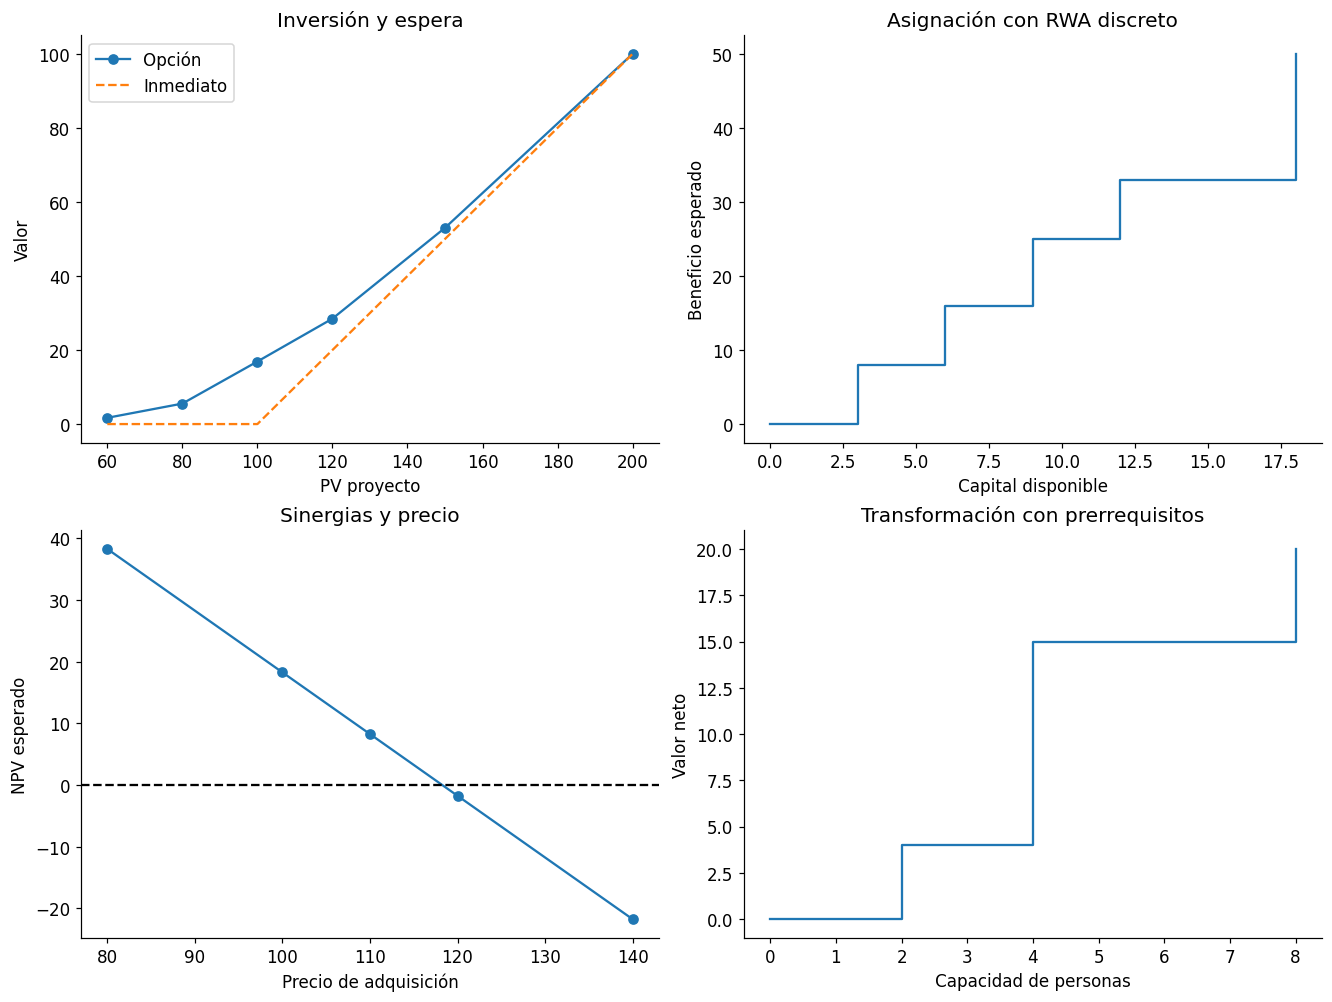

In [17]:
fig,axes=plt.subplots(2,2,figsize=(12,9),layout='constrained')
axes[0,0].plot(real_table.PV,real_table.option_value,'o-',label='Opción');axes[0,0].plot(real_table.PV,real_table.immediate,'--',label='Inmediato')
axes[0,0].set(xlabel='PV proyecto',ylabel='Valor',title='Inversión y espera');axes[0,0].legend()
axes[0,1].step(balance_table.capital,balance_table.expected_profit,where='post')
axes[0,1].set(xlabel='Capital disponible',ylabel='Beneficio esperado',title='Asignación con RWA discreto')
axes[1,0].plot(ma_table.price,ma_table.expected_npv,'o-');axes[1,0].axhline(0,color='black',linestyle='--')
axes[1,0].set(xlabel='Precio de adquisición',ylabel='NPV esperado',title='Sinergias y precio')
axes[1,1].step(transformation_table.capacity,transformation_table.net_value,where='post')
axes[1,1].set(xlabel='Capacidad de personas',ylabel='Valor neto',title='Transformación con prerrequisitos')
plt.show()

## Interpretación y próximos contrastes
Las tablas dejan observar cambios de acción y regiones donde un input no tiene efecto porque otra restricción domina. El motor OKR, por ejemplo, es un contrato de score, mientras el de capital resuelve una búsqueda combinatoria; no deben confundirse ambos como modelos predictivos.

Para uso empresarial harían falta inputs aprobados, definición del problema de decisión, calibración de probabilidades, análisis de error de estimación y revisión independiente. Se preservan las limitaciones de cada README y no se eleva el estado de madurez de los motores por añadir este notebook.